# BÀI THỰC HÀNH CHƯƠNG 2: TOÁN TỬ ĐIỂM ẢNH & LỌC TUYẾN TÍNH

---

**Mục tiêu**:
1. Hiểu và cài đặt các **toán tử điểm ảnh** (point operations): thay đổi độ sáng, độ tương phản, biến đổi âm bản, cắt ngưỡng.
2. Hiểu bản chất **phép tích chập (convolution)** trong ảnh số và cách kernel quyết định kết quả đầu ra.
3. Cài đặt và so sánh các **bộ lọc tuyến tính**: lọc trung bình, lọc Gaussian, làm nét.
4. Áp dụng các **bộ phát hiện biên** (Sobel, Prewitt) thông qua đạo hàm bậc 1.
5. Nắm **quy luật tổng hệ số kernel** và mối liên hệ giữa đạo hàm — kernel — hành vi bộ lọc.

## 📋 Bảng Lộ Trình Thực Thi Chuẩn Hóa (Execution Roadmap)

| Step | Description | What it does | Import path |
| :---: | :--- | :--- | :--- |
| **1** | **Setup & Nạp ảnh** | Nạp thư viện, đọc ảnh mẫu BGR, tạo bản grayscale | `—` |
| **2** | **Point Operations (YC1–4)** | Brightness `f+β`, Contrast `α·f`, Negative `255-f`, Threshold nhị phân | [`src/data/filters.py`](../../src/data/filters.py) |
| **3** | **Linear Filters (YC5–7)** | Mean (box), Gaussian, Sharpen `Identity − Laplacian` | [`src/data/filters.py`](../../src/data/filters.py) |
| **4** | **Edge Detection (YC8)** | Sobel X/Y, Prewitt X/Y, độ lớn gradient `√(Gx²+Gy²)` | [`src/data/filters.py`](../../src/data/filters.py) |
| **5** | **Kernel Sum Rule (YC9)** | Kiểm chứng `output = c·Σkernel` với tổng `0.5 / 1 / 2 / 0` | [`src/data/filters.py`](../../src/data/filters.py) |
| **6** | **Non-linear Filters (YC10)** | Median và Bilateral trên ảnh nhiễu muối tiêu | [`src/data/filters.py`](../../src/data/filters.py) |
| **7** | **Comparison (YC11)** | Lưới so sánh tổng hợp toàn bộ bộ lọc | [`src/pipelines/lab02_pipeline.py`](../../src/pipelines/lab02_pipeline.py) |

---

### 🔗 Tài Liệu & Báo Cáo Kỹ Thuật Liên Quan (Documentation References)

- 📋 **Đặc Tả Yêu Cầu Bài Lab**: [`docs/labs/lab02/LAB_02_DESCRIPTION.md`](../../docs/labs/lab02/LAB_02_DESCRIPTION.md)
- 📄 **Báo Cáo Kỹ Thuật Chi Tiết**: [`docs/labs/lab02/LAB_02_REPORT.md`](../../docs/labs/lab02/LAB_02_REPORT.md)
- 🌐 **Báo Cáo Trực Quan HTML**: [`docs/labs/lab02/LAB_02_REPORT.html`](../../docs/labs/lab02/LAB_02_REPORT.html)
- 🏠 **Tài Liệu Toàn Dự Án**: [`README.md`](../../README.md)

## 0. Chuẩn Bị: Nạp Thư Viện & Ảnh Mẫu

Nạp các thư viện cốt lõi, đọc ảnh mẫu ở hệ màu **BGR** (mặc định OpenCV) và tạo bản **grayscale** để dùng cho các bước phân tích cường độ (threshold, gradient).

Ảnh mẫu là **ảnh màu** để thấy rõ hiệu ứng âm bản / tương phản.

Hàm hỗ trợ `show_grid`: hiển thị dãy ảnh kèm chú thích trên một lưới gọn — tự chuyển **BGR → RGB** để đúng màu, và có thể **chuẩn hoá thang hiển thị** (percentile 99) cho ảnh gradient.

In [1]:
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cấu hình hiển thị inline cho Matplotlib
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 80
plt.rcParams["image.interpolation"] = "nearest"

print(f"Python {sys.version.split()[0]} | OpenCV {cv2.__version__} | NumPy {np.__version__}")


def show_grid(images, titles, ncols=None, normalize_display=False):
    # Lưới ảnh kèm chú thích; tự BGR->RGB và chuẩn hoá percentile 99 khi cần.
    ncols = ncols or len(images)
    nrows = (len(images) + ncols - 1) // ncols
    axes = np.atleast_1d(plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.2 * nrows))[1]).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, img, title in zip(axes, images, titles):
        disp = np.abs(img.astype(np.float32)) if normalize_display else img
        if normalize_display:
            disp = disp / (np.percentile(disp, 99) or 1.0) * 255.0
        disp = np.clip(disp, 0, 255).astype(np.uint8)
        if disp.ndim == 3:
            disp = cv2.cvtColor(disp, cv2.COLOR_BGR2RGB)
        ax.imshow(disp, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


Python 3.12.7 | OpenCV 5.0.0 | NumPy 2.2.6


Ảnh       : ..\..\data\samples\image-2.jpg
Shape BGR : (1080, 1920, 3) (H, W, C)
Shape Gray: (1080, 1920)
Dtype     : uint8


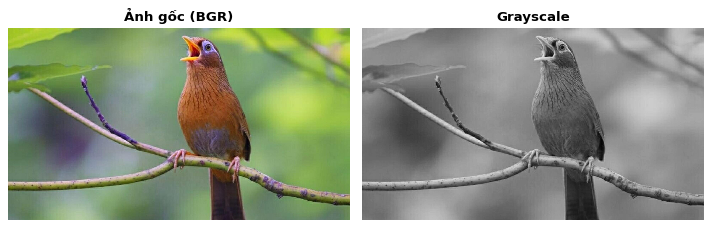

In [2]:
# Đường dẫn ảnh mẫu (hỗ trợ chạy từ repo root hoặc từ notebooks/labs/)
image_path = Path("../../data/samples/image-2.jpg")
if not image_path.exists():
    image_path = Path("data/samples/image-2.jpg")

img_bgr = cv2.imread(str(image_path))
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

print(f"Ảnh       : {image_path}")
print(f"Shape BGR : {img_bgr.shape} (H, W, C)")
print(f"Shape Gray: {img_gray.shape}")
print(f"Dtype     : {img_bgr.dtype}")

show_grid([img_bgr, img_gray], ["Ảnh gốc (BGR)", "Grayscale"])


## Yêu cầu 1: Thay Đổi Độ Sáng (Brightness)

Cộng/trừ hằng số `β` vào mỗi điểm ảnh: `g(x, y) = f(x, y) + β`.
Lưu ý **bão hoà (clipping)**: giá trị vượt `[0, 255]` phải được cắt biên bằng `np.clip`.

β = +50: min/max = [50, 255]
β = -50: min/max = [0, 205]


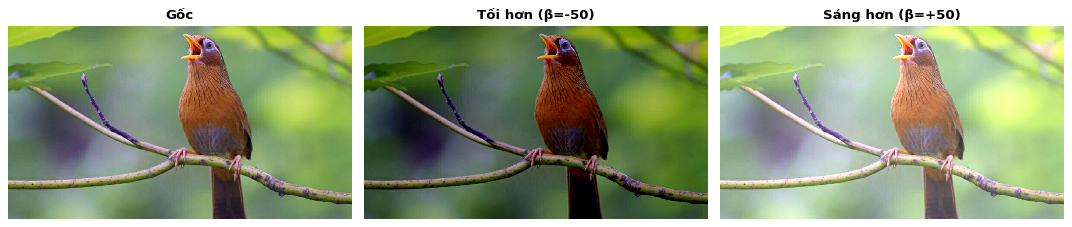

In [3]:
beta = 50
img_bright = np.clip(img_bgr.astype(np.int16) + beta, 0, 255).astype(np.uint8)
img_dark = np.clip(img_bgr.astype(np.int16) - beta, 0, 255).astype(np.uint8)

print(f"β = +{beta}: min/max = [{img_bright.min()}, {img_bright.max()}]")
print(f"β = -{beta}: min/max = [{img_dark.min()}, {img_dark.max()}]")

show_grid(
    [img_bgr, img_dark, img_bright],
    ["Gốc", f"Tối hơn (β=-{beta})", f"Sáng hơn (β=+{beta})"],
)

## Yêu cầu 2: Thay Đổi Độ Tương Phản (Contrast)

Nhân mỗi điểm ảnh với hằng số `α`: `g(x, y) = α · f(x, y)`.

- `α > 1`: ảnh tương phản mạnh hơn.
- `0 < α < 1`: ảnh "bạc màu" hơn.

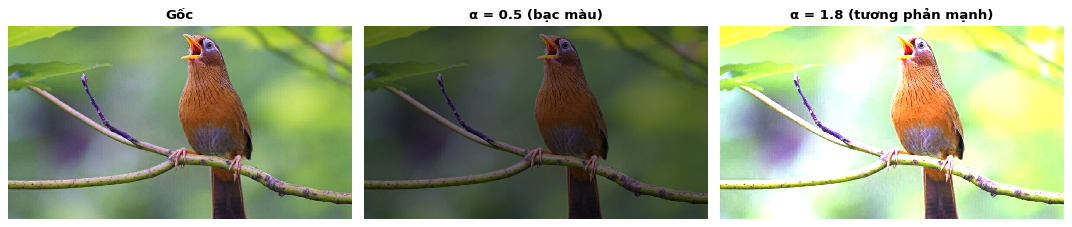

In [4]:
alpha_low, alpha_high = 0.5, 1.8
img_contrast_low = np.clip(img_bgr.astype(np.float32) * alpha_low, 0, 255).astype(np.uint8)
img_contrast_high = np.clip(img_bgr.astype(np.float32) * alpha_high, 0, 255).astype(np.uint8)

show_grid(
    [img_bgr, img_contrast_low, img_contrast_high],
    ["Gốc", f"α = {alpha_low} (bạc màu)", f"α = {alpha_high} (tương phản mạnh)"],
)

## Yêu cầu 3: Biến Đổi Âm Bản (Negative)

Đảo ngược giá trị điểm ảnh: `g(x, y) = 255 − f(x, y)`.
Ứng dụng: quan sát rõ chi tiết ở vùng tối của ảnh.

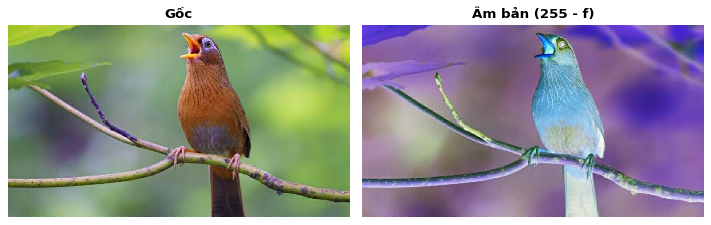

In [5]:
img_negative = 255 - img_bgr

show_grid([img_bgr, img_negative], ["Gốc", "Âm bản (255 - f)"])

## Yêu cầu 4: Cắt Ngưỡng (Thresholding)

Tạo ảnh nhị phân: `g = 255` nếu `f > T`, ngược lại `g = 0`.

**Vì sao chọn `T = 80, 127, 180`?**
- `127` là **trung điểm** của dải cường độ `[0, 255]` — mốc "trung tính" để tham chiếu.
- `80` và `180` lệch **±50** quanh trung điểm, đại diện cho ngưỡng **thấp** và **cao**.

Đây chỉ là 3 mốc minh hoạ cho xu hướng; đề bài chỉ yêu cầu "thử nhiều giá trị `T`".

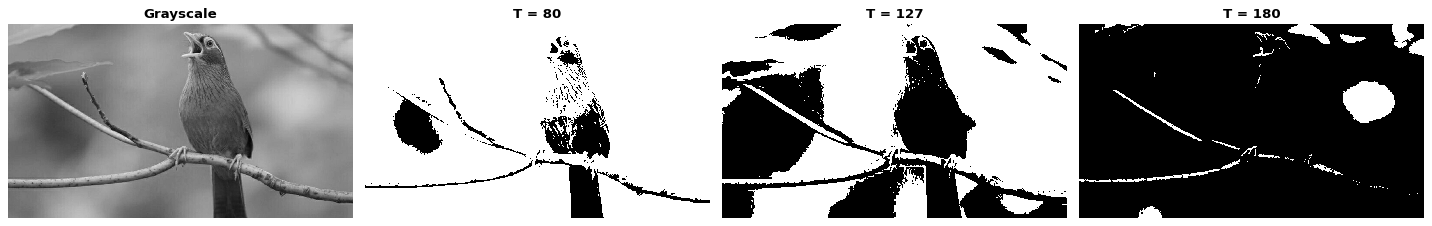

In [6]:
# 127 = trung điểm [0, 255]; 80 và 180 = ±50 quanh trung điểm (thấp / trung bình / cao)
thresholds = [80, 127, 180]
binaries = [cv2.threshold(img_gray, t, 255, cv2.THRESH_BINARY)[1] for t in thresholds]

show_grid(
    [img_gray] + binaries,
    ["Grayscale"] + [f"T = {t}" for t in thresholds],
    ncols=4,
)

## Yêu cầu 5: Lọc Trung Bình (Mean Filter)

Làm mờ bằng cách lấy **trung bình cộng** các điểm ảnh lân cận (kernel toàn số dương, tổng = 1).
So sánh kernel **7×7** và **21×21** để thấy rõ chênh lệch, đối chiếu với `cv2.blur()` của OpenCV: kernel càng lớn → mờ càng nhiều (21×21 gần như xoá sạch chi tiết nhỏ).


Mean 7x7  : sum = 1.00
Mean 21x21: sum = 1.00


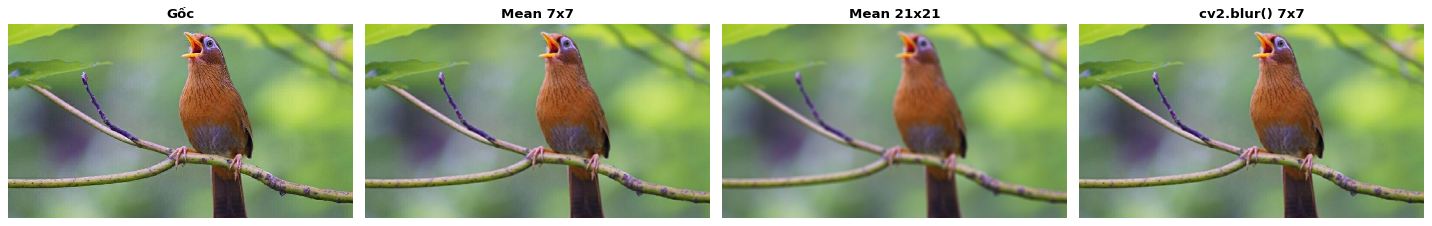

In [7]:
mean_k7 = np.ones((7, 7), dtype=np.float32) / 49.0
mean_k21 = np.ones((21, 21), dtype=np.float32) / 441.0

print(f"Mean 7x7  : sum = {mean_k7.sum():.2f}")
print(f"Mean 21x21: sum = {mean_k21.sum():.2f}")

img_mean7 = cv2.filter2D(img_bgr, -1, mean_k7)
img_mean21 = cv2.filter2D(img_bgr, -1, mean_k21)
img_blur_cv2 = cv2.blur(img_bgr, (7, 7))  # đối chiếu với OpenCV

show_grid(
    [img_bgr, img_mean7, img_mean21, img_blur_cv2],
    ["Gốc", "Mean 7x7", "Mean 21x21", "cv2.blur() 7x7"],
    ncols=4,
)


## Yêu cầu 6: Lọc Gaussian (Gaussian Filter)

Làm mờ bằng kernel Gaussian: trọng số giảm dần theo khoảng cách tới tâm (tổng = 1).
So với lọc trung bình, Gaussian **giữ cạnh tốt hơn** và mờ tự nhiên hơn. Đối chiếu với `cv2.GaussianBlur()` và tăng mạnh `sigma`: `σ` càng lớn thì mờ càng mạnh.

**Lưu ý kích thước kernel:** để Gaussian không bị **cắt cụt (truncated)**, cần `ksize ≈ 6σ + 1` (đủ ±3σ mỗi bên).
Nếu ksize quá nhỏ so với σ (ví dụ σ=7 mà k=5) thì kernel bị cắt phẳng → **thoái hoá thành lọc trung bình**. Do đó:
- `σ = 3.0` → `ksize = 19` (6×3+1)
- `σ = 7.0` → `ksize = 43` (6×7+1)


Gaussian 19x19 (sigma=3.0): sum = 1.0000


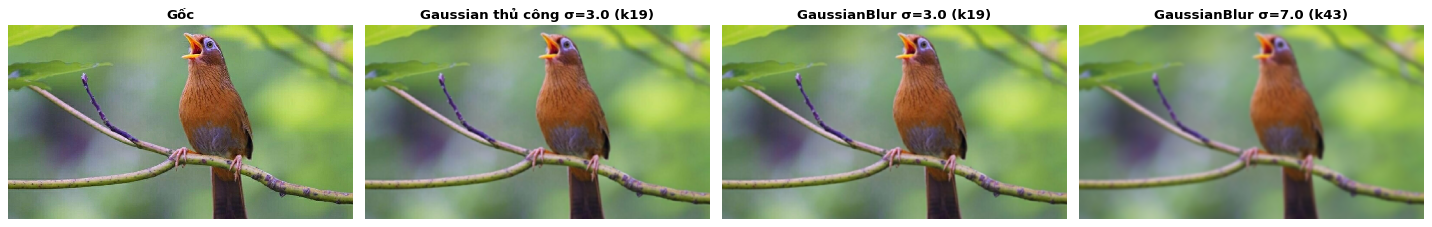

In [8]:
# Kernel Gaussian tách được: tích ngoài của vector 1D (ksize = 6σ+1 để tránh cắt cụt)
g1d_s3 = cv2.getGaussianKernel(19, sigma=3.0)
gauss_k19 = g1d_s3 @ g1d_s3.T
print(f"Gaussian 19x19 (sigma=3.0): sum = {gauss_k19.sum():.4f}")

img_gauss_manual = cv2.filter2D(img_bgr, -1, gauss_k19)
img_gauss_s30 = cv2.GaussianBlur(img_bgr, (19, 19), sigmaX=3.0)
img_gauss_s70 = cv2.GaussianBlur(img_bgr, (43, 43), sigmaX=7.0)

show_grid(
    [img_bgr, img_gauss_manual, img_gauss_s30, img_gauss_s70],
    ["Gốc", "Gaussian thủ công σ=3.0 (k19)",
     "GaussianBlur σ=3.0 (k19)", "GaussianBlur σ=7.0 (k43)"],
    ncols=4,
)


## Yêu cầu 7: Làm Sắc Nét (Sharpening)

**Bản chất:** làm nét = **Ảnh gốc + thành phần biên**, tức `Identity − Laplacian`.

- Kernel làm nét kinh điển (tâm dương lớn, xung quanh âm) có **tổng = 1**.
- **Laplacian** (`[0 1 0; 1 -4 1; 0 1 0]`, tổng = 0) là **bộ phát hiện biên**, KHÔNG phải bộ làm nét.
- Muốn làm nét từ Laplacian: lấy `Ảnh gốc − Laplacian`. Vì `Identity (tổng 1) − Laplacian (tổng 0) = tổng 1`.

Hệ số âm ở lân cận giúp **khuếch đại chênh lệch** giữa tâm và vùng xung quanh → đường biên sắc hơn.

Ở đây ta **chỉ dùng trực tiếp kernel làm nét** (đã gộp sẵn phép `Identity − Laplacian`); Laplacian thuần chỉ dùng để phát hiện biên.


Sharpen kernel: sum = 1  (tổng = 1 -> giữ nguyên độ sáng)


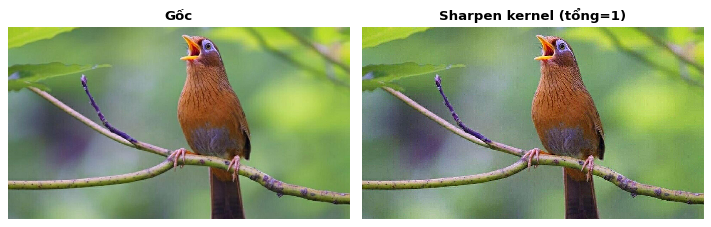

In [9]:
# Kernel làm nét = Identity − Laplacian (tâm dương lớn, lân cận âm), tổng = 1
sharpen_k = np.array([[0, -1, 0],
                      [-1, 5, -1],
                      [0, -1, 0]], dtype=np.float32)

print(f"Sharpen kernel: sum = {sharpen_k.sum():.0f}  (tổng = 1 -> giữ nguyên độ sáng)")

img_sharpen = cv2.filter2D(img_bgr, -1, sharpen_k)

show_grid(
    [img_bgr, img_sharpen],
    ["Gốc", "Sharpen kernel (tổng=1)"],
    ncols=2,
)


## Yêu cầu 8: Phát Hiện Cạnh Bằng Sobel & Prewitt

Đạo hàm bậc 1 theo hai phương:

- **Sobel** (nhấn mạnh hàng giữa): `[-1 0 1; -2 0 2; -1 0 1]`, tổng = 0.
- **Prewitt** (hệ số đều): `[-1 0 1; -1 0 1; -1 0 1]`, tổng = 0.

**Vì sao hai phương pháp cho kết quả gần giống nhau?** Hai kernel **chỉ khác duy nhất ở trọng số hàng giữa** (`2` so với `1`); các hàng còn lại y hệt. Vì vậy trên ảnh tự nhiên, ảnh biên của Sobel và Prewitt gần như trùng nhau (tương quan ≈ 1); khác biệt chủ yếu là **biên độ**.

Vì tổng = 0 nên vùng phẳng bị triệt tiêu, chỉ còn biên. Độ lớn gradient tổng hợp: `|G| = √(Gx² + Gy²)`. Ta **chuẩn hoá thang hiển thị** để ảnh gradient không bị tối đen.

Sobel X :
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
  sum = 0
Prewitt X :
[[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]
  sum = 0  (chỉ khác Sobel ở hàng giữa: 1 thay vì 2)

Tương quan Sobel vs Prewitt     : 0.9997  (~1 -> gần như trùng cấu trúc)
Biên độ trung bình Sobel        : 12.5  (lớn hơn Prewitt vì nhấn hàng giữa)
Biên độ trung bình Prewitt      : 9.3


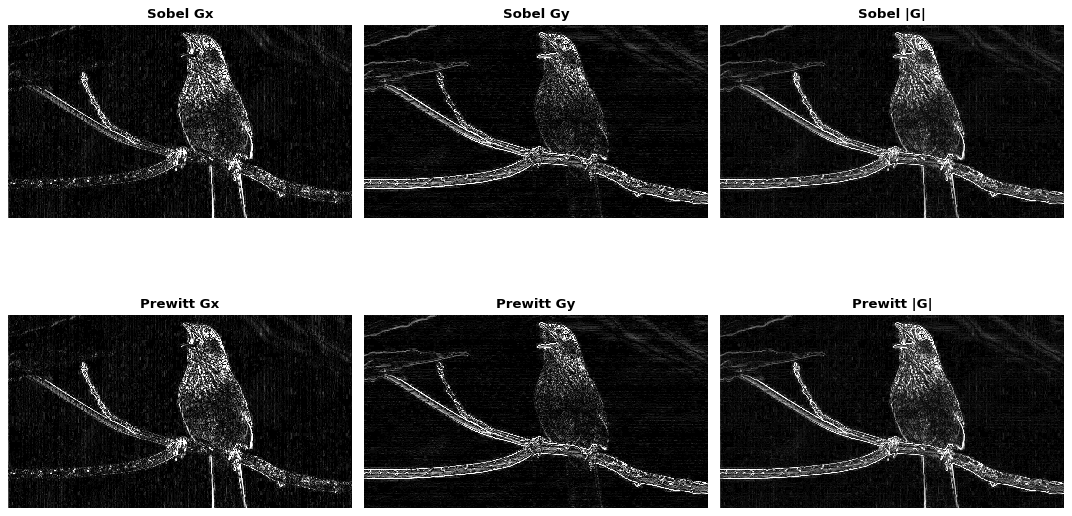

In [10]:
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)

print("Sobel X :")
print(sobel_x)
print(f"  sum = {sobel_x.sum():.0f}")
print("Prewitt X :")
print(prewitt_x)
print(f"  sum = {prewitt_x.sum():.0f}  (chỉ khác Sobel ở hàng giữa: 1 thay vì 2)")

# Đạo hàm theo X và Y (Y dùng chuyển vị của kernel X)
gx_sobel = cv2.filter2D(img_gray, cv2.CV_32F, sobel_x)
gy_sobel = cv2.filter2D(img_gray, cv2.CV_32F, sobel_x.T)
sobel_mag = cv2.magnitude(gx_sobel, gy_sobel)

gx_prewitt = cv2.filter2D(img_gray, cv2.CV_32F, prewitt_x)
gy_prewitt = cv2.filter2D(img_gray, cv2.CV_32F, prewitt_x.T)
prewitt_mag = cv2.magnitude(gx_prewitt, gy_prewitt)

# So sánh định lượng: hai bộ phát hiện biên gần như tương đương
corr = np.corrcoef(sobel_mag.ravel(), prewitt_mag.ravel())[0, 1]
print()
print(f"Tương quan Sobel vs Prewitt     : {corr:.4f}  (~1 -> gần như trùng cấu trúc)")
print(f"Biên độ trung bình Sobel        : {sobel_mag.mean():.1f}  (lớn hơn Prewitt vì nhấn hàng giữa)")
print(f"Biên độ trung bình Prewitt      : {prewitt_mag.mean():.1f}")

show_grid(
    [np.abs(gx_sobel), np.abs(gy_sobel), sobel_mag,
     np.abs(gx_prewitt), np.abs(gy_prewitt), prewitt_mag],
    ["Sobel Gx", "Sobel Gy", "Sobel |G|",
     "Prewitt Gx", "Prewitt Gy", "Prewitt |G|"],
    ncols=3,
    normalize_display=True,
)

## Yêu cầu 9: Tự Thiết Kế Kernel & Hiểu Ý Nghĩa Tổng Hệ Số

Trên một vùng ảnh **phẳng** (mọi pixel = `c`), tích chập cho `output = c × (tổng hệ số kernel)`:

1. **Tổng = 0** → xoá vùng phẳng, chỉ giữ biên (nhóm đạo hàm / phát hiện biên).
2. **Tổng = 1** → giữ nguyên độ sáng trung bình. Tổng = 1 **vẫn có thể là làm mờ** (mean, Gaussian) chứ chưa chắc là làm nét.
3. Điều kiện để kernel **thực sự làm nét**: tổng = 1 **VÀ** có hệ số âm (khuếch đại chênh lệch tâm–lân cận).

**Kiểm chứng** bằng vùng phẳng `c = 100` với các kernel có tổng lần lượt `0.5, 1, 2, 0`.
Vì vùng phẳng có mọi pixel bằng nhau (min = max), khi hiển thị phải **khoá thang màu cố định `[0, 255]`** — nếu để tự co giãn thì mọi mức xám đều bị vẽ thành đen và không so sánh được.
Sau đó áp cùng bộ kernel lên **ảnh màu** (từng kênh B/G/R) để thấy tác dụng: tối hơn / giữ nguyên / sáng hơn / **chỉ còn viền** (kernel tổng = 0):

Tổng = 0.5: sum=+0.50 -> output =  50 (kỳ vọng 50)
Tổng = 1.0: sum=+1.00 -> output = 100 (kỳ vọng 100)
Tổng = 2.0: sum=+2.00 -> output = 200 (kỳ vọng 200)
Tổng = 0.0: sum=+0.00 -> output =   0 (kỳ vọng 0)


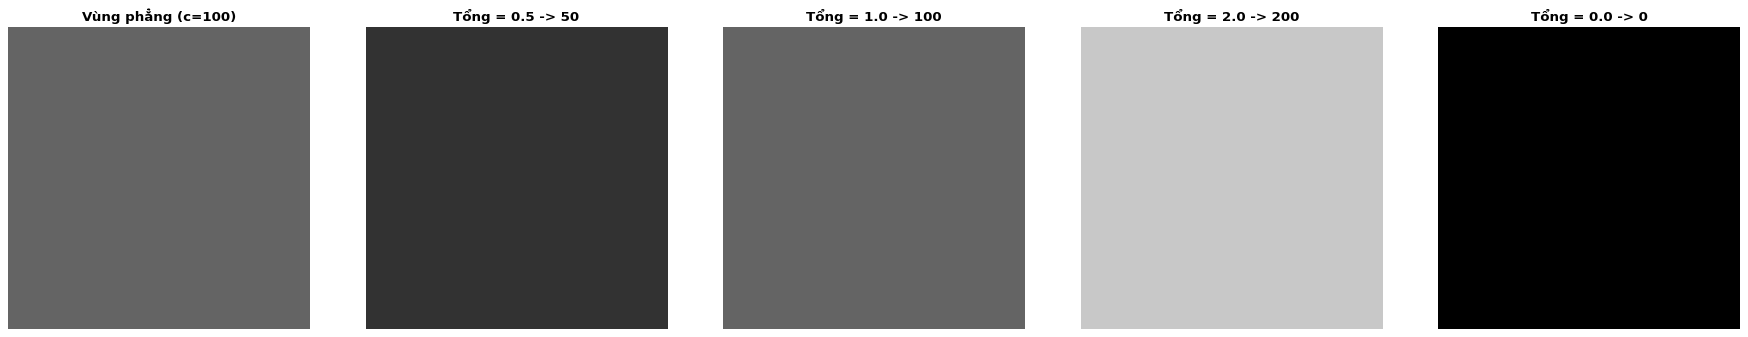

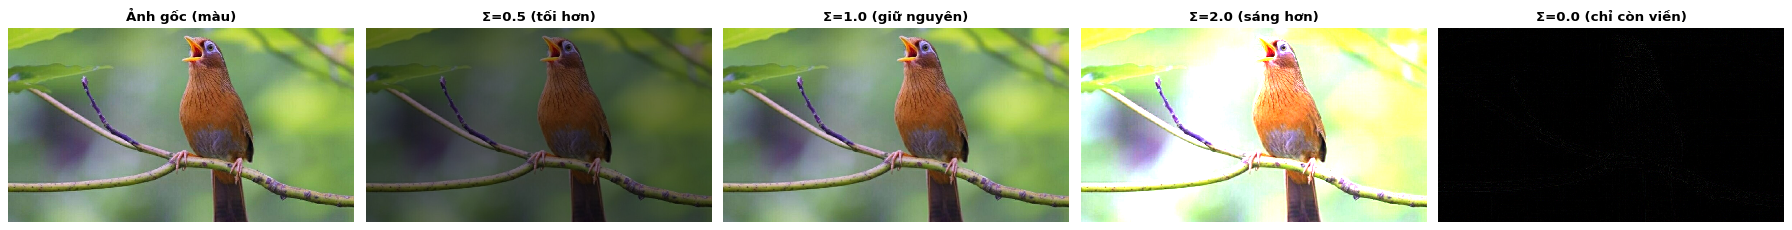

In [11]:
flat = np.full((64, 64), 100, dtype=np.uint8)

kernel_cases = {
    "Tổng = 0.5": np.full((3, 3), 0.5 / 9, dtype=np.float32),
    "Tổng = 1.0": np.full((3, 3), 1.0 / 9, dtype=np.float32),
    "Tổng = 2.0": np.full((3, 3), 2.0 / 9, dtype=np.float32),
    "Tổng = 0.0": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32),
}

figs, titles = [flat], ["Vùng phẳng (c=100)"]
for label, kern in kernel_cases.items():
    out = cv2.filter2D(flat, -1, kern)
    val = int(np.unique(out)[0])
    print(f"{label}: sum={kern.sum():+.2f} -> output = {val:>3} (kỳ vọng {100 * kern.sum():.0f})")
    figs.append(out)
    titles.append(f"{label} -> {val}")

show_grid(figs, titles)

# Áp cùng bộ kernel tự chế lên ảnh thật (image.png) để thấy tác dụng thực tế
img_effects = [img_bgr] + [cv2.filter2D(img_bgr, -1, k) for k in kernel_cases.values()]
img_effect_titles = [
    "Ảnh gốc (màu)",
    "Σ=0.5 (tối hơn)",
    "Σ=1.0 (giữ nguyên)",
    "Σ=2.0 (sáng hơn)",
    "Σ=0.0 (chỉ còn viền)",
]
show_grid(img_effects, img_effect_titles, ncols=5)

## Yêu cầu 10: Lọc Phi Tuyến Tính (Non-linear Filters)

- **Median** (`cv2.medianBlur`): thay pixel bằng **trung vị** vùng lân cận → rất hiệu quả với nhiễu muối tiêu.
- **Bilateral** (`cv2.bilateralFilter`): kết hợp **không gian** và **cường độ** → làm mờ vùng đồng nhất nhưng giữ cạnh.

Các lọc này **không thể** biểu diễn bằng một kernel tích chập vì kết quả không phải tổ hợp tuyến tính có trọng số cố định của lân cận.

Ta thêm nhiễu muối tiêu (3%) vào ảnh rồi áp **cả hai bộ lọc lên cùng ảnh nhiễu đó** để so sánh:
Median xoá mạnh điểm nhiễu; Bilateral chỉ giảm nhẹ vì là trung bình có trọng số.

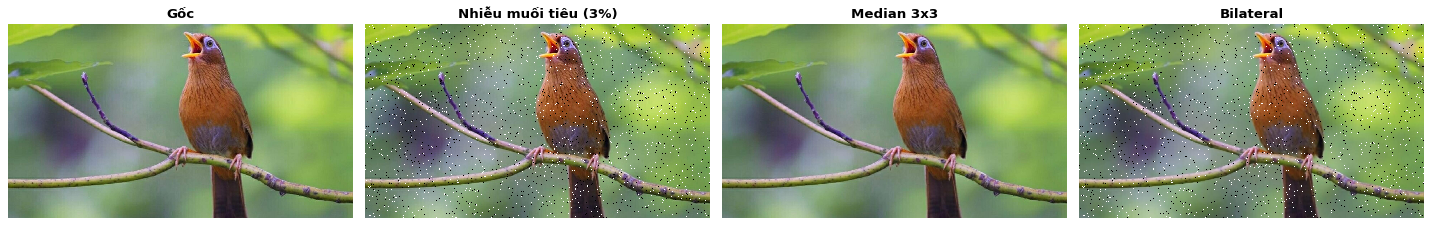

In [12]:
# Thêm nhiễu muối tiêu (salt & pepper) với seed cố định để tái lập kết quả
rng = np.random.default_rng(42)
img_noisy = img_bgr.copy()
prob = 0.03
mask = rng.random(img_noisy.shape[:2])
img_noisy[mask < prob / 2] = 0        # muối (đen)
img_noisy[mask > 1 - prob / 2] = 255  # tiêu (trắng)

img_median = cv2.medianBlur(img_noisy, 3)
img_bilateral = cv2.bilateralFilter(img_noisy, d=9, sigmaColor=75, sigmaSpace=75)

show_grid(
    [img_bgr, img_noisy, img_median, img_bilateral],
    ["Gốc", "Nhiễu muối tiêu (3%)", "Median 3x3", "Bilateral"],
)

## Yêu cầu 11: So Sánh Tổng Hợp Các Bộ Lọc

Áp tất cả bộ lọc lên cùng một ảnh và quan sát trong lưới duy nhất để đối chiếu mức độ **làm mờ / làm nét / giữ cạnh / khử nhiễu**.

- Lưới 1 (ảnh màu): các bộ lọc giữ ảnh / làm mờ / làm nét / khử nhiễu.
- Lưới 2 (ảnh gradient): các bộ phát hiện biên, đã chuẩn hoá thang hiển thị.

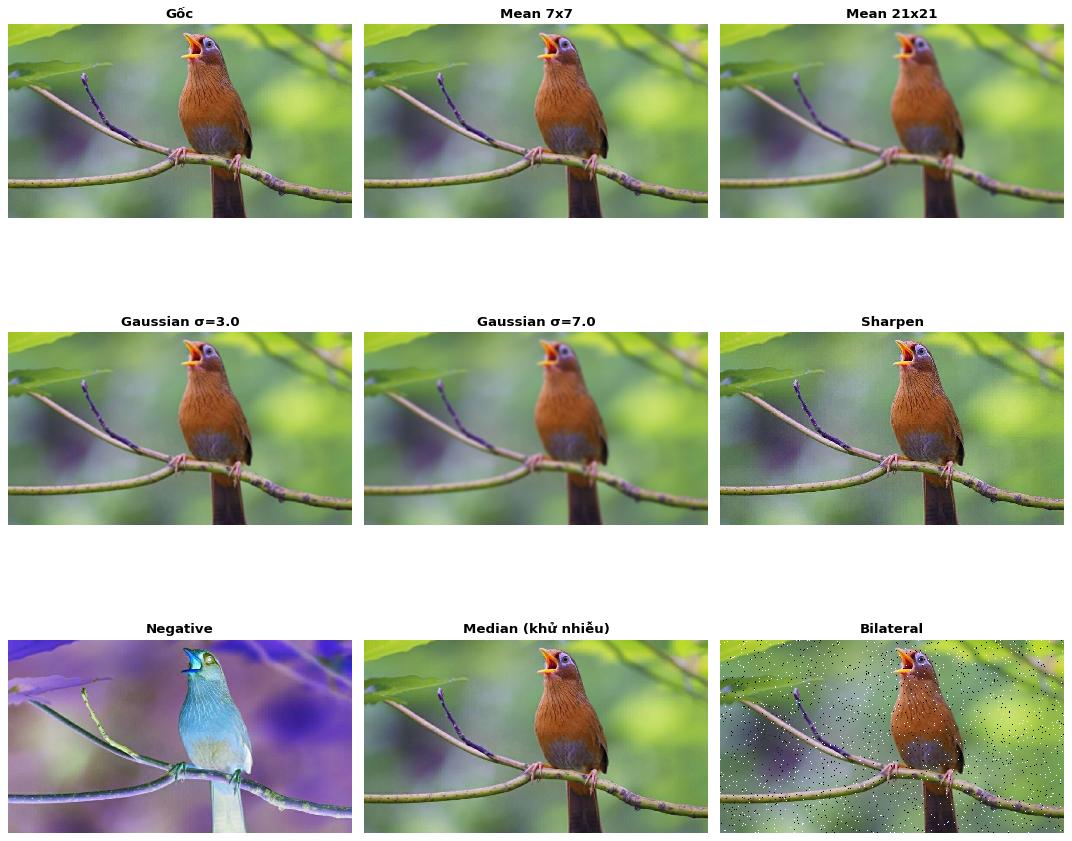

In [13]:
show_grid(
    [img_bgr, img_mean7, img_mean21, img_gauss_s30, img_gauss_s70,
     img_sharpen, img_negative, img_median, img_bilateral],
    ["Gốc", "Mean 7x7", "Mean 21x21", "Gaussian σ=3.0", "Gaussian σ=7.0",
     "Sharpen", "Negative", "Median (khử nhiễu)", "Bilateral"],
    ncols=3,
)


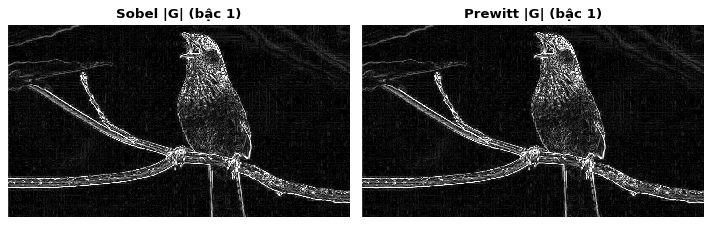

In [14]:
show_grid(
    [sobel_mag, prewitt_mag],
    ["Sobel |G| (bậc 1)", "Prewitt |G| (bậc 1)"],
    ncols=2,
    normalize_display=True,
)


## Tổng Kết

| Bộ lọc | Loại | Tổng kernel | Tác dụng chính |
| :--- | :--- | :---: | :--- |
| Mean (box) | Tuyến tính | 1 | Làm mờ đều, mất chi tiết |
| Gaussian | Tuyến tính | 1 | Làm mờ tự nhiên, giữ cạnh tốt hơn mean |
| Sharpen | Tuyến tính | 1 | Tăng chi tiết biên (`Identity − Laplacian`) |
| Sobel | Tuyến tính | 0 | Phát hiện biên (đạo hàm bậc 1) |
| Prewitt | Tuyến tính | 0 | Phát hiện biên (hệ số đều) |
| Laplacian | Tuyến tính | 0 | Phát hiện biên (đạo hàm bậc 2) |
| Median | Phi tuyến | — | Khử nhiễu muối tiêu rất tốt |
| Bilateral | Phi tuyến | — | Khử nhiễu, giữ cạnh sắc nét |

**Kết luận cốt lõi**:
- **Tổng kernel = 1** ⇒ bảo toàn độ sáng (có thể là mờ hoặc nét tuỳ dấu hệ số).
- **Tổng kernel = 0** ⇒ triệt tiêu vùng phẳng, chỉ giữ biên (nhóm đạo hàm).
- Làm nét thật sự cần **tổng = 1 và có hệ số âm**.
- **Sobel và Prewitt** chỉ khác trọng số hàng giữa → kết quả gần như tương đương trên ảnh tự nhiên.
- Lọc **phi tuyến** (median, bilateral) không biểu diễn được bằng một kernel tích chập.